# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

**Дисциплина:** «Анализ больших данных и рыночных тенденций»  
**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Формат:** интерактивный ноутбук Google Colab · до 100 баллов · срок сдачи — по графику курса

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

1. Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.
2. Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.
3. Нормализовать «грязные» поля (цены, остатки, зарплатные вилки, даты, технологии в тексте требований) регулярными выражениями.
4. Собрать единый `pandas.DataFrame`, провести разведочный анализ и построить корректные графики.
5. Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|---|---|
| Сбор | `requests` (+ `urllib3.Retry`), открытые REST API, кэш ответов на диске |
| Разбор HTML | `BeautifulSoup4` (CSS-селекторы), `lxml` (XPath) |
| Очистка | `re` — регулярные выражения |
| Анализ и графики | `pandas`, `numpy`, `matplotlib`, `seaborn` |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук **со всеми выводами ячеек**, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся **ссылка на репозиторий**. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

## Как работать с этим ноутбуком

1. **Файл → Сохранить копию на Диске.** Работайте только в своей копии.
2. В ячейке «Шаг 1» задайте **номер варианта** (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.
3. Выполняйте ячейки **строго сверху вниз**. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».
4. Места, которые нужно дописать, помечены `TODO`. Пока шаг не выполнен, ячейка честно падает с `NotImplementedError` — это нормально.
5. Перед сдачей запустите ячейку **самопроверки**: она должна показать «Выполнено: 11 из 11».

### Три правила вежливого сбора данных

* **Пауза между запросами.** `REQUEST_PAUSE = 0.5` секунды — нижняя граница для учебной работы. Сервер, который вы «положите», принадлежит другим людям.
* **Кэш включён по умолчанию.** Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите `USE_CACHE` или очистите папку кэша.
* **Никаких ключей в коде.** Токены читаются функцией `get_secret()` из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. **Выводы по аварийным данным не принимаются** — повторите сбор, когда источник снова доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

**API** — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

* **Эндпоинт** — «ручка» сервиса: `/vacancies`, `/works`, `/search/repositories`.
* **Параметры** уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
* **Заголовки** описывают клиента. `User-Agent` с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.
* **Коды ответа** — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать `r.json()` |
| 301 / 302 | адрес изменился | проверить итоговый `r.url` |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать `Retry-After`, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | `page`, `per_page` | GitHub, OpenAlex |
| Смещение и размер | `offset`, `limit` | «Работа в России» |
| Курсор | `cursor`, `next` | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем `per_page`, — данные закончились. Бесконечный `while True` без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

* пауза между запросами (`time.sleep`);
* повторные попытки с **экспоненциальной задержкой** — в работе это `urllib3.Retry(backoff_factor=1.5)`: 1,5 с → 3 с → 6 с;
* уважение заголовков `X-RateLimit-Remaining` и `Retry-After`;
* кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть **Secrets** (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через `userdata.get("MY_KEY")`. В работе это обёрнуто в `get_secret()`.

### Что изменилось к 2026 году (важно для выбора источника)

* **hh.ru**: с апреля 2026 публичный метод `GET /vacancies` отвечает `403 Forbidden` на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал **«Работа в России»** (`opendata.trudvsem.ru`), данные Роструда, ключ не нужен.
* **OpenAlex**: с 13 февраля 2026 всем запросам нужен бесплатный `api_key`, параметр `mailto` и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы `search` дороже, чем `filter`, а получение объекта по идентификатору бесплатно. Отсюда практический приём: `per-page=100` и фильтры вместо поиска.
* **GitHub**: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: **источник — это не константа**. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в **DOM** — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

| | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | `soup.select("article.product_pod p.price_color")` | `tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()')` |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | `el.get("title")` | `.../@title` |
| Текст | `el.get_text(" ", strip=True)` | `.../text()` |
| Поиск по тексту | `soup.find("th", string="UPC")` | `//th[text()="UPC"]` |
| Движение «вверх» и «вбок» | `el.parent`, `el.find_next_sibling()` | оси: `parent::`, `following-sibling::`, `ancestor::` |
| Условие по числу | средствами Python | `[position() <= 3]`, `[last()]` |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

**Когда что удобнее.** CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```python
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

1. **Цепляйтесь за смысл, а не за форму.** `div > div > div:nth-child(3)` сломается при первом же редизайне; `p.price_color` переживёт его.
2. **Проверяйте на нескольких страницах.** Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.
3. **Отсутствие элемента — норма.** `select_one()` вернёт `None`; парсер должен записать `None` в поле, а не падать.
4. **Сверяйте два способа.** В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.
5. **Динамические сайты.** Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от `"от 60 000 до 90 000 руб."` к паре `(60000, 90000)`.

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| `\d`, `\w`, `\s` | цифра, буква/цифра/подчёркивание, пробельный символ | `\d{4}` — год |
| `+`, `*`, `?`, `{n,m}` | повторения | `\d{1,3}` |
| `(?P<name>...)` | именованная группа | `(?P<min>\d+)` → `m.group("min")` |
| `(?:...)` | группировка без захвата | `(?:руб\.?|₽)` |
| `[...]`, `[^...]` | символьный класс и его отрицание | `[£$€₽]` |
| `\b` | граница слова | `\bBI\b` не совпадёт внутри `BigData` |
| `?` после квантификатора | ленивый режим | `<.+?>` |
| `re.I`, `re.S`, `re.X` | флаги: регистр, `.` включая перевод строки, «читаемый» режим | |

Функции: `re.search` — первое совпадение, `re.findall` — все, `re.sub` — замена, `re.compile` — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | `(?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?)` | в `1 250,50 ₽` стоит **неразрывный** пробел `\u00a0`, а десятичный разделитель — запятая |
| Остаток | `\((?P<n>\d+)\s*available\)` | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | `(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?` | «по договорённости» → `(None, None)`; одиночное число — это и нижняя, и верхняя граница |
| Дата | `(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})` и `\d{4}-\d{2}-\d{2}` | в одном источнике встречаются оба формата |
| Технология в тексте | `(?<![\w])(python|sql|power bi)(?![\w])` | без границ `bi` найдётся в «combined» |

### Чего делать не нужно

* **Разбирать HTML регулярками.** Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.
* **Писать одно «универсальное» выражение на все случаи.** Проще и надёжнее несколько маленьких функций с тестами.
* **Верить, что очистка прошла успешно.** Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

* **`robots.txt` и пользовательское соглашение.** Перед сбором смотрим `https://сайт/robots.txt` и раздел об использовании данных. Запрет в `robots.txt` — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.
* **Нагрузка.** Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.
* **Персональные данные.** Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.
* **Авторские права и лицензии.** Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.
* **Прозрачность.** В `User-Agent` указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны **учебные витрины** (`books.toscrape.com`, `quotes.toscrape.com`, `webscraper.io/test-sites`, `scrapethissite.com`), созданные специально для тренировки, и **открытые государственные и научные данные**. Навык переносится на коммерческие источники, а юридические риски — нет.

### Шаг 1. Окружение, параметры варианта и работа с ключами

**Зачем мы это делаем.** Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый `User-Agent` с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

* `Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))` — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
* `polite_get()` никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
* `get_secret()` ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [12]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 17              #@param {type:"slider", min:1, max:30, step:1}
CONTACT_EMAIL = "makarovaep@mgpu.ru"  #@param {type:"string"}
USE_CACHE = True          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()
CACHE_DIR = Path("/content/pw1_cache" if Path("/content").exists() else "pw1_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.

    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta

    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta

    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta

    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            data = r.json()
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        data = r.text
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.13.16 | requests 2.32.4 | bs4 4.13.5 | lxml 6.1.3 | pandas 2.2.3 | seaborn 0.13.2
Вариант: 17 | кэш: /content/pw1_cache | пауза между запросами: 0.5 с


**Как читать вывод.** В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Если пауза меньше 0,5 с, увеличьте её: при сборе десятков страниц это разница между «данные собраны» и «IP временно заблокирован».

In [13]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"area": "HR-аналитика",
"task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
"api": "trudvsem",
"api_params": {
"text": "инженер машинного обучения",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
},
{
"id": 2,
"area": "E-commerce",
"task": "Ценовое позиционирование в нише деловой литературы",
"api": "trudvsem",
"api_params": {
"text": "аналитик маркетплейсов",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
},
{
"id": 3,
"area": "Финтех",
"task": "Валютный риск закупок: динамика USD и EUR за квартал",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 90
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
},
{
"id": 4,
"area": "Мониторинг конкурентов",
"task": "Сравнение ассортимента двух товарных категорий",
"api": "github",
"api_params": {
"q": "price monitoring",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "fiction_10",
"pages": 4
},
"metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
},
{
"id": 5,
"area": "Наука и инновации",
"task": "Научная активность в сфере FinTech: динамика публикаций",
"api": "openalex",
"api_params": {
"search": "fintech",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "quotes",
"site_params": {
"tag": "inspirational",
"pages": 4
},
"metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
},
{
"id": 6,
"area": "Логистика",
"task": "Погодные риски на складских хабах: планирование окон отгрузки",
"api": "openmeteo",
"api_params": {
"cities": [
"Москва",
"Екатеринбург",
"Новосибирск"
],
"days": 14
},
"site": "books",
"site_params": {
"category": "history_32",
"pages": 2
},
"metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
},
{
"id": 7,
"area": "HR-аналитика",
"task": "Спрос на дата-инженеров и требования к стеку",
"api": "trudvsem",
"api_params": {
"text": "инженер данных",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
},
{
"id": 8,
"area": "E-commerce",
"task": "Влияние рейтинга на цену: есть ли премия за качество",
"api": "github",
"api_params": {
"q": "recommender system",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "romance_8",
"pages": 4
},
"metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
},
{
"id": 9,
"area": "Финтех",
"task": "Стоимость валютной корзины импортёра",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 120
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
},
{
"id": 10,
"area": "Мониторинг конкурентов",
"task": "Глубина ассортимента и «дыры» в наличии у конкурента",
"api": "trudvsem",
"api_params": {
"text": "категорийный менеджер",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "mystery_3",
"pages": 4
},
"metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
},
{
"id": 11,
"area": "Наука и инновации",
"task": "Публикационный ландшафт по теме «supply chain analytics»",
"api": "openalex",
"api_params": {
"search": "supply chain analytics",
"from_year": 2020,
"per_page": 100,
"pages": 2
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
},
{
"id": 12,
"area": "Логистика",
"task": "Температурный режим перевозок: risk-календарь на две недели",
"api": "openmeteo",
"api_params": {
"cities": [
"Санкт-Петербург",
"Казань",
"Краснодар"
],
"days": 14
},
"site": "webscraper",
"site_params": {
"section": "computers/tablets",
"pages": 3
},
"metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
},
{
"id": 13,
"area": "HR-аналитика",
"task": "BI-аналитики: сколько стоит и что требуют работодатели",
"api": "trudvsem",
"api_params": {
"text": "BI аналитик",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
},
{
"id": 14,
"area": "Технологические тренды",
"task": "Экосистема инструментов парсинга: кто лидирует",
"api": "github",
"api_params": {
"q": "web scraping",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "quotes",
"site_params": {
"tag": "books",
"pages": 3
},
"metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
},
{
"id": 15,
"area": "E-commerce",
"task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
"api": "trudvsem",
"api_params": {
"text": "менеджер интернет-магазина",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "childrens_11",
"pages": 4
},
"metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
},
{
"id": 16,
"area": "Финтех",
"task": "Курс юаня и импорт электроники: чувствительность цены",
"api": "cbr",
"api_params": {
"currencies": [
"CNY"
],
"days": 180
},
"site": "webscraper",
"site_params": {
"section": "phones/touch",
"pages": 2
},
"metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
},
{
"id": 17,
"area": "Наука и инновации",
"task": "Исследования по «digital twin» в промышленности",
"api": "openalex",
"api_params": {
"search": "digital twin manufacturing",
"from_year": 2018,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
},
{
"id": 18,
"area": "Мониторинг конкурентов",
"task": "Сравнение цен и «звёздности» ассортимента двух категорий",
"api": "github",
"api_params": {
"q": "e-commerce analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "food-and-drink_33",
"pages": 3
},
"metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
},
{
"id": 19,
"area": "HR-аналитика",
"task": "Логистические профессии: дефицит кадров по регионам",
"api": "trudvsem",
"api_params": {
"text": "логист",
"pages": 6,
"per_page": 100
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
},
{
"id": 20,
"area": "Логистика",
"task": "Окна доставки в северных хабах на горизонте 16 дней",
"api": "openmeteo",
"api_params": {
"cities": [
"Мурманск",
"Архангельск",
"Якутск"
],
"days": 16
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
},
{
"id": 21,
"area": "E-commerce",
"task": "Автоматизация мониторинга: как часто меняется наличие товара",
"api": "github",
"api_params": {
"q": "price tracker",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "sequential-art_5",
"pages": 4
},
"metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
},
{
"id": 22,
"area": "Финтех",
"task": "Волатильность рубля как фактор ценообразования",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 365
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
},
{
"id": 23,
"area": "HR-аналитика",
"task": "Продуктовые аналитики: требования и вилки",
"api": "trudvsem",
"api_params": {
"text": "продуктовый аналитик",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "humor",
"pages": 3
},
"metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
},
{
"id": 24,
"area": "Технологические тренды",
"task": "Инструменты работы с данными: Python-экосистема",
"api": "github",
"api_params": {
"q": "pandas alternative dataframe",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
},
{
"id": 25,
"area": "Наука и инновации",
"task": "Публикации по «marketplace pricing»: кто задаёт повестку",
"api": "openalex",
"api_params": {
"search": "marketplace pricing",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
},
{
"id": 26,
"area": "Логистика",
"task": "Планирование складских смен по погодным окнам",
"api": "openmeteo",
"api_params": {
"cities": [
"Ростов-на-Дону",
"Самара",
"Пермь"
],
"days": 14
},
"site": "scrapethissite",
"site_params": {
"section": "hockey",
"pages": 2
},
"metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
},
{
"id": 27,
"area": "Мониторинг конкурентов",
"task": "Бенчмарк цен на технику: разброс внутри линейки",
"api": "trudvsem",
"api_params": {
"text": "менеджер по закупкам",
"pages": 4,
"per_page": 100
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
},
{
"id": 28,
"area": "E-commerce",
"task": "Влияние глубины каталога на средний чек (гипотеза)",
"api": "github",
"api_params": {
"q": "shopping cart analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "poetry_23",
"pages": 4
},
"metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
},
{
"id": 29,
"area": "Финтех",
"task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 180
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
},
{
"id": 30,
"area": "E-commerce + HR (эталон преподавателя)",
"task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
"api": "trudvsem",
"api_params": {
"text": "аналитик данных",
"pages": 3,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
}
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}

def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))

Вариант 17 — Наука и инновации
Бизнес-задача: Исследования по «digital twin» в промышленности

Источник API : api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)
Параметры API: {'search': 'digital twin manufacturing', 'from_year': 2018, 'per_page': 100, 'pages': 2}
Сайт парсинга: books.toscrape.com (учебная витрина интернет-магазина)
Параметры    : {'category': 'science_22', 'pages': 3}

Метрики и визуализации:
  Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости


### Шаг 2. Сбор данных через открытый API

**Зачем мы это делаем.** API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

* остановка цикла, когда страница вернула меньше записей, чем запрошено;
* обращение к вложенным полям **только** через `.get()` — в открытых данных заполнены не все поля;
* печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

In [14]:
#@title Шаг 2. Сбор данных OpenAlex
def fetch_api(cfg):
    p = cfg["api_params"]
    key = os.environ.get("OPENALEX_API_KEY")
    try:
        from google.colab import userdata
        key = key or userdata.get("OPENALEX_API_KEY")
    except Exception:
        pass
    rows = []
    for page in range(1, p["pages"] + 1):
        params = {"search": p["search"], "filter": "from_publication_date:%s-01-01" % p["from_year"], "per-page": p["per_page"], "page": page}
        if key:
            params["api_key"] = key
        data, meta = polite_get("https://api.openalex.org/works", params=params)
        if data is None:
            print("Ошибка API, статус:", meta.get("status"), "Проверьте OPENALEX_API_KEY в Secrets")
            break
        batch = data.get("results", [])
        print("Страница", page, "публикаций", len(batch), "кэш", meta.get("from_cache"))
        rows.extend(batch)
        if len(batch) < p["per_page"]:
            break
    return rows

def normalize_api(rows, cfg):
    return pd.DataFrame([{ "id": r.get("id"), "title": r.get("display_name"), "publication_year": r.get("publication_year"), "publication_date": r.get("publication_date"), "cited_by_count": r.get("cited_by_count"), "is_oa": r.get("open_access", {}).get("is_oa"), "authors": [{"id": a.get("author", {}).get("id"), "name": a.get("author", {}).get("display_name")} for a in r.get("authorships", [])]} for r in rows])

api_rows = fetch_api(CFG)
df_api = normalize_api(api_rows, CFG)
API_SOURCE = "openalex" if len(df_api) else "unavailable"
print("Получено публикаций:", len(df_api), "Синтетические данные не используются")
if api_rows:
    print("Ключи первой записи:", list(api_rows[0]))
display(df_api.head())

Страница 1 публикаций 100 кэш True
Страница 2 публикаций 100 кэш True
Получено публикаций: 200 Синтетические данные не используются
Ключи первой записи: ['id', 'doi', 'title', 'display_name', 'relevance_score', 'publication_year', 'publication_date', 'ids', 'language', 'primary_location', 'volume', 'type', 'indexed_in', 'open_access', 'authorships', 'institutions', 'countries_distinct_count', 'institutions_distinct_count', 'corresponding_author_ids', 'corresponding_institution_ids', 'apc_list', 'apc_paid', 'fwci', 'has_fulltext', 'cited_by_count', 'citation_normalized_percentile', 'cited_by_percentile_year', 'biblio', 'is_retracted', 'is_paratext', 'is_xpac', 'primary_topic', 'topics', 'keywords', 'concepts', 'mesh', 'locations_count', 'locations', 'best_oa_location', 'sustainable_development_goals', 'sustainable_development_goals_aurora', 'study_designs', 'awards', 'funders', 'has_content', 'content_urls', 'referenced_works_count', 'referenced_works', 'related_works', 'abstract_invert

,id,title,publication_year,publication_date,cited_by_count,is_oa,authors
0,https://openalex.org/W2941765731,Knowledge-driven digital twin manufacturing ce...,2019,2019-04-25,423,False,"[{'id': 'https://openalex.org/A5024783234', 'n..."
1,https://openalex.org/W2955282155,A data- and knowledge-driven framework for dig...,2019,2019-01-01,141,True,"[{'id': 'https://openalex.org/A5100739850', 'n..."
2,https://openalex.org/W4327709650,A digital thread-driven distributed collaborat...,2023,2023-03-17,93,False,"[{'id': 'https://openalex.org/A5100692295', 'n..."
3,https://openalex.org/W4386373632,Knowledge-Driven Digital Twin Manufacturing,2023,2023-01-01,1,False,"[{'id': 'https://openalex.org/A5039660670', 'n..."
4,https://openalex.org/W4386373638,Fault diagnosis in digital twin manufacturing,2023,2023-01-01,1,False,"[{'id': 'https://openalex.org/A5068573207', 'n..."


**Как читать вывод.** Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак `из кэша`: при повторном запуске сеть не используется, поэтому для свежих данных выключайте `USE_CACHE`.

Если в выводе появилось предупреждение об аварийном режиме, значит источник недоступен: пайплайн продолжит работу на синтетических данных, но выводы по ним недопустимы.

### Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

**Зачем мы это делаем.** Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это **контроль качества**: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию `SITES`: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

In [15]:
#@title Шаг 3. BeautifulSoup и XPath
from urllib.parse import urljoin
SITES = {"books": {"item_css": "article.product_pod", "item_xpath": "//article[contains(@class, 'product_pod')]", "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"), "availability_text": ("p.availability", "text"), "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")}, "fields_xpath": {"title": ".//h3/a/@title", "price_text": ".//p[@class='price_color']/text()", "availability_text": ".//p[contains(@class, 'availability')]//text()", "rating_class": ".//p[contains(@class, 'star-rating')]/@class", "url": ".//h3/a/@href"}}}

def parse_with_bs4(html, site):
    cfg = SITES[site]
    rows = []
    for node in BeautifulSoup(html, "html.parser").select(cfg["item_css"]):
        row = {}
        for field, (selector, attr) in cfg["fields_css"].items():
            el = node.select_one(selector)
            row[field] = None if el is None else (el.get_text(" ", strip=True) if attr == "text" else " ".join(el.get("class", [])) if attr == "class" else el.get(attr))
        rows.append(row)
    return rows

def parse_with_xpath(html, site):
    cfg = SITES[site]
    rows = []
    for node in lxml_html.fromstring(html).xpath(cfg["item_xpath"]):
        row = {}
        for field, expr in cfg["fields_xpath"].items():
            values = [str(v).strip() for v in node.xpath(expr) if str(v).strip()]
            row[field] = " ".join(values) if values else None
        rows.append(row)
    return rows

def collect_site(site, pages=3, category=None, **kw):
    base = "https://books.toscrape.com/catalogue/category/books/" + category + "/index.html"
    sources = [(base, category)]
    bs_rows, xp_rows = [], []
    # В Science всего 14 книг: добавляем отдельно помеченный общий каталог,
    # чтобы выполнить минимум 40 карточек без дублирования и подмены ниши.
    sources.append(("https://books.toscrape.com/catalogue/page-1.html", "general_supplement"))
    seen = set()
    for start, label in sources:
        url = start
        for page in range(1, pages + 1):
            html, meta = polite_get(url, expect="text")
            if html is None:
                print("Ошибка загрузки", label, page, meta.get("status"))
                break
            bs, xp = parse_with_bs4(html, site), parse_with_xpath(html, site)
            assert bs == xp, "Расхождение полей BS4/XPath"
            for a, b in zip(bs, xp):
                absolute = urljoin(url, a["url"])
                if absolute in seen:
                    continue
                seen.add(absolute)
                for row in (a, b):
                    row.update(url=absolute, category=label, source_page=page)
                bs_rows.append(a)
                xp_rows.append(b)
            print(label, "страница", page, "карточек", len(bs))
            next_link = BeautifulSoup(html, "html.parser").select_one("li.next a")
            if not next_link or (label == "general_supplement" and len(bs_rows) >= 40):
                break
            url = urljoin(url, next_link.get("href"))
    return bs_rows, xp_rows

rows_bs4, rows_xpath = collect_site(CFG["site"], **CFG["site_params"])
df_web = pd.DataFrame(rows_bs4)
WEB_SOURCE = "books"
titles_bs4 = [r.get("title") for r in rows_bs4]
titles_xpath = [r.get("title") for r in rows_xpath]
same = sum(a == b for a, b in zip(titles_bs4, titles_xpath))
print("Карточек:", len(df_web), "Полное совпадение:", rows_bs4 == rows_xpath)
display(df_web.head())

science_22 страница 1 карточек 14
general_supplement страница 1 карточек 20
general_supplement страница 2 карточек 20
Карточек: 54 Полное совпадение: True


,title,price_text,availability_text,rating_class,url,category,source_page
0,The Most Perfect Thing: Inside (and Outside) a...,Â£42.96,In stock,star-rating Four,https://books.toscrape.com/catalogue/the-most-...,science_22,1
1,Immunity: How Elie Metchnikoff Changed the Cou...,Â£57.36,In stock,star-rating Five,https://books.toscrape.com/catalogue/immunity-...,science_22,1
2,Sorting the Beef from the Bull: The Science of...,Â£44.74,In stock,star-rating Four,https://books.toscrape.com/catalogue/sorting-t...,science_22,1
3,Tipping Point for Planet Earth: How Close Are ...,Â£37.55,In stock,star-rating One,https://books.toscrape.com/catalogue/tipping-p...,science_22,1
4,"The Fabric of the Cosmos: Space, Time, and the...",Â£55.91,In stock,star-rating One,https://books.toscrape.com/catalogue/the-fabri...,science_22,1


**Как читать вывод.** Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Проверьте также, что число карточек соответствует ожидаемому (на учебной витрине — 20 на страницу) и что в таблице нет колонок, целиком заполненных `None`: пустая колонка — это почти всегда устаревший селектор, а не отсутствие данных на сайте.

### Шаг 4. Очистка и нормализация регулярными выражениями

**Зачем мы это делаем.** `«£47.82»`, `«In stock (22 available)»`, `«star-rating Three»`, `«от 60 000 до 90 000 руб.»` — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и **тесты** к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [16]:
#@title Шаг 4. Очистка RegEx и тесты
def parse_price(text):
    m = re.search(r"(?<!\d)(\d{1,3}(?:[\s\u00a0\u202f\u2009]\d{3})+|\d+)(?:[.,](\d{1,2}))?", str(text or ""))
    return float(re.sub(r"\s", "", m.group(1)) + ("." + m.group(2) if m.group(2) else "")) if m else None

def parse_stock(text):
    if re.search(r"out of stock", str(text), re.I):
        return 0
    m = re.search(r"\((\d+)\s*available\)", str(text), re.I)
    return int(m.group(1)) if m else None

def parse_rating(text):
    words = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
    m = re.search(r"\b(One|Two|Three|Four|Five)\b", str(text))
    return words[m.group(1)] if m else None

def parse_salary(text):
    s = str(text or "")
    lower = re.search(r"от\s*(\d[\d\s]*)", s, re.I)
    upper = re.search(r"до\s*(\d[\d\s]*)", s, re.I)
    if lower or upper:
        return (parse_price(lower.group(1)) if lower else None, parse_price(upper.group(1)) if upper else None)
    nums = re.findall(r"\d+(?:\s\d{3})*(?:[.,]\d+)?", s)
    if len(nums) == 2:
        return tuple(parse_price(x) for x in nums)
    val = parse_price(s)
    return val, val

SKILLS = ["python", "sql", "power bi", "excel", "1с", "tableau", "clickhouse", "airflow", "pandas", "spark", "hadoop", "postgresql", "bi", "dwh", "etl", "статистика", "machine learning"]
def extract_skills(text):
    found = [s for s in SKILLS if re.search(r"(?<!\w)" + re.escape(s) + r"(?!\w)", str(text), re.I)]
    if "power bi" in found and "bi" in found:
        found.remove("bi")
    return sorted(found)

def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()

def parse_date(text):
    s = str(text or "")
    m = re.search(r"\b(\d{4}-\d{2}-\d{2})\b", s)
    if m:
        return pd.to_datetime(m.group(1), errors="coerce")
    m = re.search(r"\b(\d{2})[./-](\d{2})[./-](\d{4})\b", s)
    return pd.to_datetime("%s-%s-%s" % (m.group(3), m.group(2), m.group(1)), errors="coerce") if m else pd.NaT

CASES = [(parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5), (parse_price, "по договорённости", None), (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0), (parse_rating, "star-rating Three", 3), (parse_salary, "от 60 000 до 90 000 руб.", (60000., 90000.)), (parse_salary, "по договорённости", (None, None)), (parse_date, "15.03.2026", pd.Timestamp("2026-03-15")), (extract_skills, "Нужен Python, SQL и Power BI", ["power bi", "python", "sql"]), (extract_skills, "combined BigData", [])]
for func, arg, expected in CASES:
    assert func(arg) == expected, (func.__name__, arg, func(arg))
print("Пройдено тестов RegEx:", len(CASES))
for field, source, func in [("price", "price_text", parse_price), ("stock", "availability_text", parse_stock), ("rating", "rating_class", parse_rating)]:
    df_web[field] = pd.to_numeric(df_web[source].map(func), errors="coerce")
    print(field, "распознано:", format(df_web[field].notna().mean(), ".1%"))
if len(df_api):
    df_api = df_api.drop_duplicates("id").copy()
    df_api["publication_date"] = df_api["publication_date"].map(parse_date)
    for field in ["publication_year", "cited_by_count"]:
        df_api[field] = pd.to_numeric(df_api[field], errors="coerce")
    df_api["is_oa"] = df_api["is_oa"].astype("boolean")
df_science = df_web[df_web["category"] == "science_22"].copy()
display(df_web.head())
display(df_api.head())

Пройдено тестов RegEx: 11
price распознано: 100.0%
stock распознано: 0.0%
rating распознано: 100.0%


,title,price_text,availability_text,rating_class,url,category,source_page,price,stock,rating
0,The Most Perfect Thing: Inside (and Outside) a...,Â£42.96,In stock,star-rating Four,https://books.toscrape.com/catalogue/the-most-...,science_22,1,42.96,NaN,4
1,Immunity: How Elie Metchnikoff Changed the Cou...,Â£57.36,In stock,star-rating Five,https://books.toscrape.com/catalogue/immunity-...,science_22,1,57.36,NaN,5
2,Sorting the Beef from the Bull: The Science of...,Â£44.74,In stock,star-rating Four,https://books.toscrape.com/catalogue/sorting-t...,science_22,1,44.74,NaN,4
3,Tipping Point for Planet Earth: How Close Are ...,Â£37.55,In stock,star-rating One,https://books.toscrape.com/catalogue/tipping-p...,science_22,1,37.55,NaN,1
4,"The Fabric of the Cosmos: Space, Time, and the...",Â£55.91,In stock,star-rating One,https://books.toscrape.com/catalogue/the-fabri...,science_22,1,55.91,NaN,1


,id,title,publication_year,publication_date,cited_by_count,is_oa,authors
0,https://openalex.org/W2941765731,Knowledge-driven digital twin manufacturing ce...,2019,2019-04-25,423,False,"[{'id': 'https://openalex.org/A5024783234', 'n..."
1,https://openalex.org/W2955282155,A data- and knowledge-driven framework for dig...,2019,2019-01-01,141,True,"[{'id': 'https://openalex.org/A5100739850', 'n..."
2,https://openalex.org/W4327709650,A digital thread-driven distributed collaborat...,2023,2023-03-17,93,False,"[{'id': 'https://openalex.org/A5100692295', 'n..."
3,https://openalex.org/W4386373632,Knowledge-Driven Digital Twin Manufacturing,2023,2023-01-01,1,False,"[{'id': 'https://openalex.org/A5039660670', 'n..."
4,https://openalex.org/W4386373638,Fault diagnosis in digital twin manufacturing,2023,2023-01-01,1,False,"[{'id': 'https://openalex.org/A5068573207', 'n..."


**Как читать вывод.** Сначала блок проверки регулярных выражений: пока он не показывает «все ок», данные трогать рано. Затем таблица качества очистки — доля распознанных значений по каждому источнику. Ориентир: не ниже 80 %. Если ниже, ищите формат, который выражение не покрывает (обычно это неразрывный пробел, диапазон «от … до …» или валюта, записанная словом). Помните: строки с нераспознанной ценой не исчезают — они превращаются в пропуски и молча уменьшают выборку.

### Шаг 5. Разведочный анализ и визуализация

**Зачем мы это делаем.** Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в `pandas`, а рисуем уже маленькие итоговые таблицы.

Остатки распознаны: 100.0%


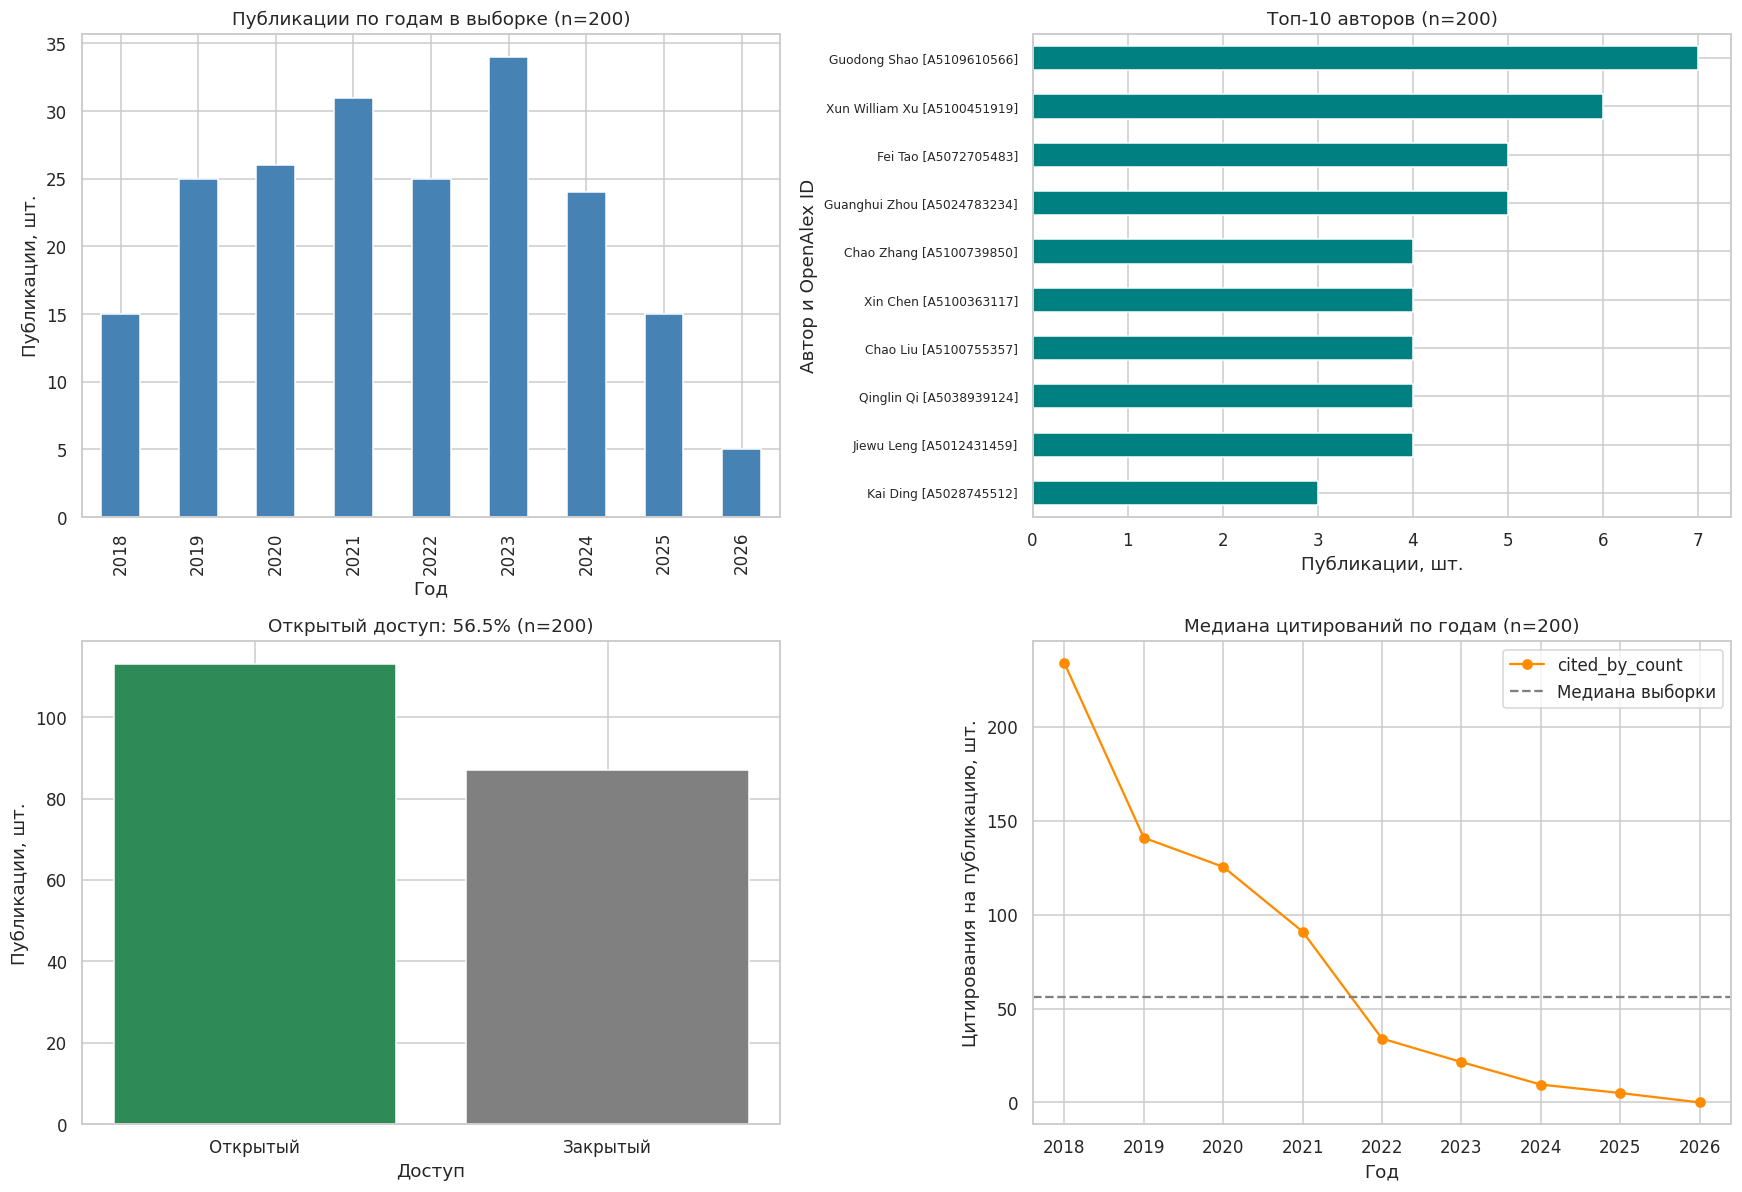

,публикаций,медиана цитирований
publication_year,,
2018,15,234.0
2019,25,141.0
2020,26,125.5
2021,31,91.0
2022,25,34.0
2023,34,21.5
2024,24,9.5
2025,15,5.0
2026,5,0.0


Первые 200 результатов по релевантности не отражают полный объём исследований по годам.


In [17]:
#@title Шаг 5. Графики варианта 17
# В списке нет количества: загружаем карточки товаров.
for idx, row in df_web.iterrows():
    detail, meta = polite_get(row["url"], expect="text")
    if detail is not None:
        el = BeautifulSoup(detail, "html.parser").select_one("p.availability")
        text = el.get_text(" ", strip=True) if el else None
        df_web.at[idx, "availability_text"] = text
        df_web.at[idx, "stock"] = parse_stock(text)
df_science = df_web[df_web.category == "science_22"].copy()
print("Остатки распознаны:", format(df_web.stock.notna().mean(), ".1%"))
assert len(df_api), "Нет данных API"
n = len(df_api)
years = df_api.groupby("publication_year").size().sort_index()
author_counts, author_names = Counter(), {}
for authors in df_api.authors:
    unique = {a["id"] or a["name"]: a for a in authors}
    for key, a in unique.items():
        if key:
            author_counts[key] += 1
            author_names[key] = a["name"] or key
top_authors = pd.Series({author_names[k] + " [" + k.rsplit("/", 1)[-1] + "]": v for k, v in author_counts.most_common(10)})
oa = df_api.is_oa.value_counts().reindex([True, False], fill_value=0)
citations = df_api.groupby("publication_year").cited_by_count.median().sort_index()
fig, ax = plt.subplots(2, 2, figsize=(16, 11))
years.plot.bar(ax=ax[0, 0], color="steelblue")
ax[0, 0].set(title=f"Публикации по годам в выборке (n={n})", xlabel="Год", ylabel="Публикации, шт.")
top_authors.sort_values().plot.barh(ax=ax[0, 1], color="teal")
ax[0, 1].set(title=f"Топ-10 авторов (n={n})", xlabel="Публикации, шт.", ylabel="Автор и OpenAlex ID")
ax[0, 1].tick_params(axis="y", labelsize=8)
ax[1, 0].bar(["Открытый", "Закрытый"], oa.values, color=["seagreen", "gray"])
ax[1, 0].set(title=f"Открытый доступ: {df_api.is_oa.mean():.1%} (n={n})", xlabel="Доступ", ylabel="Публикации, шт.")
citations.plot(marker="o", ax=ax[1, 1], color="darkorange")
ax[1, 1].axhline(df_api.cited_by_count.median(), linestyle="--", color="gray", label="Медиана выборки")
ax[1, 1].set(title=f"Медиана цитирований по годам (n={n})", xlabel="Год", ylabel="Цитирования на публикацию, шт.")
ax[1, 1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({"публикаций": years, "медиана цитирований": citations}))
print("Первые 200 результатов по релевантности не отражают полный объём исследований по годам.")

**Как читать вывод.** На гистограмме цен смотрите не на среднее, а на форму: длинный правый хвост означает, что несколько дорогих позиций тянут среднее вверх, и для отчёта корректнее медиана. На графике цен по рейтингу обращайте внимание на подписи `n=`: медиана по трём товарам — это не закономерность. На распределении остатков важна доля позиций в наличии: это прямой индикатор качества управления запасами у конкурента. На боксплоте зарплат сравнивайте медианы и ширину коробок: широкая коробка означает, что в одной и той же роли рынок платит очень по-разному, и нанимать придётся точечно.

### Шаг 6. Выводы и управленческие рекомендации

**Зачем мы это делаем.** Заказчику нужны не графики, а решения: входить ли в нишу, по какой цене, хватит ли на рынке специалистов. Метрики считаем кодом, а в текст переносим уже посчитанные значения — так вывод невозможно «придумать».

In [21]:
#@title Шаг 6. Метрики и управленческие выводы
from IPython.display import Markdown
collected_at = datetime.now(timezone(timedelta(hours=3))).isoformat(timespec="seconds")
metrics = {"публикаций": len(df_api), "доля OA": float(df_api.is_oa.mean()), "медиана цитируемости": float(df_api.cited_by_count.median()), "Q1 цитируемости": float(df_api.cited_by_count.quantile(.25)), "Q3 цитируемости": float(df_api.cited_by_count.quantile(.75)), "книг Science": len(df_science), "всего уникальных книг": len(df_web), "медиана Science, GBP": float(df_science.price.median()), "IQR Science, GBP": float(df_science.price.quantile(.75) - df_science.price.quantile(.25)), "доля в наличии Science": float((df_science.stock > 0).mean())}
summary = pd.Series(metrics, name="значение").to_frame()
display(summary)
peak_year = int(years.idxmax())
leader_id, leader_count = author_counts.most_common(1)[0]

,значение
публикаций,200.0000
доля OA,0.5650
медиана цитируемости,56.0000
Q1 цитируемости,11.0000
Q3 цитируемости,138.0000
книг Science,14.0000
всего уникальных книг,54.0000
"медиана Science, GBP",30.0250
"IQR Science, GBP",25.6275
доля в наличии Science,1.0000


В ходе работы собраны **200 публикаций о цифровых двойниках в промышленности**. Эта выборка позволяет провести первоначальный обзор технологий и найти подходы для дальнейшего изучения. Однако она включает только первые две страницы результатов поиска по релевантности, поэтому не отражает весь объём исследований по теме.

Наибольшее число публикаций в выборке относится **к 2023 году — 34 работы**. Это показывает, что работы этого года заметно представлены среди найденных материалов. Но считать 2023 год пиком развития направления нельзя: для такого вывода необходимо собрать полный корпус публикаций и сравнить полные годы.

**Открытый доступ имеют 56,5% публикаций — 113 из 200 работ**. Для предприятия это означает возможность начать изучение темы с материалов, доступных без подписки. Такой подход может сократить время и расходы на подготовку обзора, хотя наличие полного текста каждой работы следует проверить отдельно.

**Медианная цитируемость составляет 56 цитирований**, а центральные 50% публикаций имеют от 11 до 138 цитирований. Эти значения показывают заметный разброс внимания научного сообщества к найденным работам. Цитируемость можно использовать для первоначального отбора литературы, но она не доказывает эффективность описанных технологий. Кроме того, старые публикации обычно имели больше времени для накопления цитирований.

Наиболее представленным автором оказался **Guodong Shao — 7 публикаций**. Его работы можно включить в углублённый обзор, а сведения об авторе и его организации использовать при поиске экспертов. При этом количество публикаций в выборке не является оценкой качества автора.

Отдельно проанализирована учебная категория книг Science. М**едианная цена составила £30,02**, а межквартильный размах — £25,63, что указывает на заметный разброс цен. Все 14 книг категории находились в наличии на момент сбора. Эти результаты описывают только учебную витрину и не позволяют оценить реальный спрос или рынок научной литературы.

Цены, рейтинги и остатки распознаны в **100% собранных строк**. Это подтверждает полноту обработки данных, но не гарантирует достоверность информации, опубликованной источником.

С практической точки зрения результаты помогают предприятию подготовить обзор цифровых двойников, найти экспертов и выбрать несколько решений для пилота. Окончательное решение о внедрении должно опираться на результаты проверки в конкретном производственном процессе: изменение простоев, количества брака, затрат на обслуживание и стоимость самого внедрения.

**Как читать вывод.** Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель. Параметры подставляются в код автоматически по значению `VARIANT` из шага 1. Вариант 30 разобран в версии для преподавателя как эталон.

Минимальный объём выборки для зачёта по блоку 1: **не менее 50 записей из API** и **не менее 40 карточек с сайта**. Если на вашем запросе данных меньше — расширьте ключевое слово или глубину пагинации и зафиксируйте это в отчёте.

| № | Сфера | Бизнес-задача | Источник API | Сайт для парсинга | Параметры сбора | Целевые метрики и визуализации |
|---:|---|---|---|---|---|---|
| 1 | HR-аналитика | Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят | opendata.trudvsem.ru | books.toscrape.com | API: text=инженер машинного обучения, pages=5, per_page=100<br>Сайт: category=science_22, pages=3 | Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога |
| 2 | E-commerce | Ценовое позиционирование в нише деловой литературы | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик маркетплейсов, pages=4, per_page=100<br>Сайт: category=business_35, pages=3 | Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат |
| 3 | Финтех | Валютный риск закупок: динамика USD и EUR за квартал | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=90<br>Сайт: category=travel_2, pages=2 | Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли |
| 4 | Мониторинг конкурентов | Сравнение ассортимента двух товарных категорий | api.github.com | books.toscrape.com | API: q=price monitoring, sort=stars, pages=2, per_page=50<br>Сайт: category=fiction_10, pages=4 | Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки» |
| 5 | Наука и инновации | Научная активность в сфере FinTech: динамика публикаций | api.openalex.org | quotes.toscrape.com | API: search=fintech, from_year=2019, per_page=100, pages=2<br>Сайт: tag=inspirational, pages=4 | Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов |
| 6 | Логистика | Погодные риски на складских хабах: планирование окон отгрузки | api.open-meteo.com | books.toscrape.com | API: cities=['Москва', 'Екатеринбург', 'Новосибирск'], days=14<br>Сайт: category=history_32, pages=2 | Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога |
| 7 | HR-аналитика | Спрос на дата-инженеров и требования к стеку | opendata.trudvsem.ru | quotes.toscrape.com | API: text=инженер данных, pages=5, per_page=100<br>Сайт: tag=life, pages=3 | Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат |
| 8 | E-commerce | Влияние рейтинга на цену: есть ли премия за качество | api.github.com | books.toscrape.com | API: q=recommender system, sort=stars, pages=2, per_page=50<br>Сайт: category=romance_8, pages=4 | Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев |
| 9 | Финтех | Стоимость валютной корзины импортёра | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['USD', 'EUR', 'CNY'], days=120<br>Сайт: section=computers/laptops, pages=3 | Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу |
| 10 | Мониторинг конкурентов | Глубина ассортимента и «дыры» в наличии у конкурента | opendata.trudvsem.ru | books.toscrape.com | API: text=категорийный менеджер, pages=4, per_page=100<br>Сайт: category=mystery_3, pages=4 | Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям |
| 11 | Наука и инновации | Публикационный ландшафт по теме «supply chain analytics» | api.openalex.org | scrapethissite.com/pages | API: search=supply chain analytics, from_year=2020, per_page=100, pages=2<br>Сайт: section=countries, pages=1 | Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран |
| 12 | Логистика | Температурный режим перевозок: risk-календарь на две недели | api.open-meteo.com | webscraper.io/test-sites/e-commerce/allinone | API: cities=['Санкт-Петербург', 'Казань', 'Краснодар'], days=14<br>Сайт: section=computers/tablets, pages=3 | Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов |
| 13 | HR-аналитика | BI-аналитики: сколько стоит и что требуют работодатели | opendata.trudvsem.ru | books.toscrape.com | API: text=BI аналитик, pages=5, per_page=100<br>Сайт: category=business_35, pages=3 | Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости |
| 14 | Технологические тренды | Экосистема инструментов парсинга: кто лидирует | api.github.com | quotes.toscrape.com | API: q=web scraping, sort=stars, pages=2, per_page=50<br>Сайт: tag=books, pages=3 | Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды |
| 15 | E-commerce | Ценовые сегменты в детской нише: где «дыра» в предложении | opendata.trudvsem.ru | books.toscrape.com | API: text=менеджер интернет-магазина, pages=4, per_page=100<br>Сайт: category=childrens_11, pages=4 | Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей |
| 16 | Финтех | Курс юаня и импорт электроники: чувствительность цены | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['CNY'], days=180<br>Сайт: section=phones/touch, pages=2 | Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса |
| 17 | Наука и инновации | Исследования по «digital twin» в промышленности | api.openalex.org | books.toscrape.com | API: search=digital twin manufacturing, from_year=2018, per_page=100, pages=2<br>Сайт: category=science_22, pages=3 | Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости |
| 18 | Мониторинг конкурентов | Сравнение цен и «звёздности» ассортимента двух категорий | api.github.com | books.toscrape.com | API: q=e-commerce analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=food-and-drink_33, pages=3 | Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики |
| 19 | HR-аналитика | Логистические профессии: дефицит кадров по регионам | opendata.trudvsem.ru | scrapethissite.com/pages | API: text=логист, pages=6, per_page=100<br>Сайт: section=countries, pages=1 | Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн) |
| 20 | Логистика | Окна доставки в северных хабах на горизонте 16 дней | api.open-meteo.com | books.toscrape.com | API: cities=['Мурманск', 'Архангельск', 'Якутск'], days=16<br>Сайт: category=travel_2, pages=2 | Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза |
| 21 | E-commerce | Автоматизация мониторинга: как часто меняется наличие товара | api.github.com | books.toscrape.com | API: q=price tracker, sort=stars, pages=2, per_page=50<br>Сайт: category=sequential-art_5, pages=4 | Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен |
| 22 | Финтех | Волатильность рубля как фактор ценообразования | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=365<br>Сайт: category=business_35, pages=3 | Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 % |
| 23 | HR-аналитика | Продуктовые аналитики: требования и вилки | opendata.trudvsem.ru | quotes.toscrape.com | API: text=продуктовый аналитик, pages=5, per_page=100<br>Сайт: tag=humor, pages=3 | Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты |
| 24 | Технологические тренды | Инструменты работы с данными: Python-экосистема | api.github.com | webscraper.io/test-sites/e-commerce/allinone | API: q=pandas alternative dataframe, sort=stars, pages=2, per_page=50<br>Сайт: section=computers/laptops, pages=3 | Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx) |
| 25 | Наука и инновации | Публикации по «marketplace pricing»: кто задаёт повестку | api.openalex.org | books.toscrape.com | API: search=marketplace pricing, from_year=2019, per_page=100, pages=2<br>Сайт: category=business_35, pages=3 | Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога |
| 26 | Логистика | Планирование складских смен по погодным окнам | api.open-meteo.com | scrapethissite.com/pages | API: cities=['Ростов-на-Дону', 'Самара', 'Пермь'], days=14<br>Сайт: section=hockey, pages=2 | Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией |
| 27 | Мониторинг конкурентов | Бенчмарк цен на технику: разброс внутри линейки | opendata.trudvsem.ru | webscraper.io/test-sites/e-commerce/allinone | API: text=менеджер по закупкам, pages=4, per_page=100<br>Сайт: section=computers/laptops, pages=3 | Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков |
| 28 | E-commerce | Влияние глубины каталога на средний чек (гипотеза) | api.github.com | books.toscrape.com | API: q=shopping cart analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=poetry_23, pages=4 | Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев |
| 29 | Финтех | Кросс-курсы и арбитраж: USD, EUR, CNY за полгода | cbr.ru | quotes.toscrape.com | API: currencies=['USD', 'EUR', 'CNY'], days=180<br>Сайт: tag=life, pages=3 | Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат |
| 30 | E-commerce + HR (эталон преподавателя) | Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик данных, pages=3, per_page=100<br>Сайт: category=business_35, pages=3 | Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков |

## Критерии оценки (до 10 баллов)

| Блок | Что оценивается | Максимум |
|---|---|---:|
| 1. Сбор данных | Корректная пагинация и остановка цикла; паузы и повторные попытки; обработка кодов ответа и исключений (`try/except`, проверка `status_code`); объём выборки не ниже минимума варианта; понятный лог сбора | 25 |
| 2. Очистка, RegEx и XPath | Рабочие селекторы CSS **и** XPath, сверка результатов; регулярные выражения с тестами; доля распознанных значений ≥ 80 %; итоговый `DataFrame` с типизированными колонками | 25 |
| 3. EDA и визуализация | Не менее четырёх графиков из варианта; подписанные оси и единицы измерения; указан объём выборки; выбраны устойчивые метрики (медиана, квартили); графики читаются без пояснений | 25 |
| 4. Бизнес-выводы | Выводы опираются на посчитанные числа; сформулированы действия, а не наблюдения; указаны ожидаемый эффект и способ проверки; честно названы ограничения | 25 |

### Шкала

| Баллы | Оценка |
|---|---|
| 8-10 | отлично |
| 7-8 | хорошо |
| 5-6 | удовлетворительно |
| < 5 | работа возвращается на доработку |

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Ключ, токен или пароль в коде либо в выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок («жёсткий» цикл по страницам) | −1,0 |
| Выводы на аварийных (синтетических) данных без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 (длина строки, именование) | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Сдан файл вместо ссылки на репозиторий; ноутбук без выводов ячеек | −1,0 |

**Дополнительно:** задание со звёздочкой в конце ноутбука — до +1,0 баллов сверх рубрики (но итог не выше 2).

In [19]:
#@title Самопроверка варианта 17
# В исходном шаблоне пункты зарплат и навыков предназначены для HR.
# Для OpenAlex проверяем вместо них даты/цитируемость и авторов/OA.
checks = []
def check(name, condition):
    checks.append((name, bool(condition)))
check("Вариант 17", VARIANT == 17)
check("API: не менее 50 реальных публикаций", len(df_api) >= 50)
check("HTML: не менее 40 уникальных карточек", len(df_web) >= 40 and df_web.url.is_unique)
check("Полное совпадение полей BS4 и XPath", rows_bs4 == rows_xpath and same == len(titles_bs4) and same > 0)
check("Числовые поля цены и рейтинга", pd.api.types.is_numeric_dtype(df_web.price) and pd.api.types.is_numeric_dtype(df_web.rating))
check("Цена распознана не менее чем в 80% строк", df_web.price.notna().mean() >= .8)
check("Даты и цитируемость заполнены не менее чем в 80%", len(df_api) > 0 and df_api.publication_date.notna().mean() >= .8 and df_api.cited_by_count.notna().mean() >= .8)
check("Извлечены авторы и статус открытого доступа", len(df_api) > 0 and df_api.authors.map(len).gt(0).mean() >= .8 and df_api.is_oa.notna().mean() >= .8)
check("Паузы, ретраи и журнал", REQUEST_PAUSE >= .5 and len(REQUEST_LOG) > 0 and SESSION.get_adapter("https://").max_retries.total >= 1)
secret_like = [k for k, v in list(globals().items()) if isinstance(v, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", v)]
check("Нет ключей в глобальных строковых переменных", not secret_like)
check("Реальные источники", API_SOURCE == "openalex" and WEB_SOURCE == "books")
ok = sum(passed for _, passed in checks)
print(f"Выполнено: {ok} из {len(checks)}")
for name, passed in checks:
    print("✅" if passed else "❌", name)
print("Остатки распознаны:", format(df_web.stock.notna().mean(), ".1%"))
assert ok == len(checks), "Есть незакрытые проверки"

Выполнено: 11 из 11
✅ Вариант 17
✅ API: не менее 50 реальных публикаций
✅ HTML: не менее 40 уникальных карточек
✅ Полное совпадение полей BS4 и XPath
✅ Числовые поля цены и рейтинга
✅ Цена распознана не менее чем в 80% строк
✅ Даты и цитируемость заполнены не менее чем в 80%
✅ Извлечены авторы и статус открытого доступа
✅ Паузы, ретраи и журнал
✅ Нет ключей в глобальных строковых переменных
✅ Реальные источники
Остатки распознаны: 100.0%


## Задание со звёздочкой (до +2 баллов)

Разовый сбор данных — учебная задача. Производственная задача — **мониторинг**: данные собираются регулярно, источник меняется, а система не должна разваливаться. Ниже пять направлений; выберите одно и доведите до измеримого результата.

In [20]:
#@title Задание E. Устойчивость парсеров
def parse_checked(html, method):
    rows = method(html, "books")
    for row in rows:
        issues = []
        if not row.get("title"):
            issues.append("missing_title")
        if parse_price(row.get("price_text")) is None:
            issues.append("invalid_price")
        row["issues"] = issues
        row["problematic"] = bool(issues)
    return rows
base_html = """<article class="product_pod"><h3><a title="Test">Test</a></h3><p class="price_color">£12.50</p></article>"""
mutations = [("исходная карточка", base_html, False), ("нет названия", base_html.replace('<h3><a title="Test">Test</a></h3>', ""), True), ("пустая цена", base_html.replace("£12.50", ""), True), ("изменён класс", base_html.replace("price_color", "new-price"), True)]
results = []
for name, html, expected in mutations:
    for method in [parse_with_bs4, parse_with_xpath]:
        rows = parse_checked(html, method)
        assert len(rows) == 1 and rows[0]["problematic"] == expected
        results.append({"случай": name, "парсер": method.__name__, "проблемная": rows[0]["problematic"], "причины": rows[0]["issues"], "тест": "OK"})
display(pd.DataFrame(results))
print("Пройдено 8 из 8 тестов. Парсеры не падают, проблемные строки помечены.")

,случай,парсер,проблемная,причины,тест
0,исходная карточка,parse_with_bs4,False,[],OK
1,исходная карточка,parse_with_xpath,False,[],OK
2,нет названия,parse_with_bs4,True,[missing_title],OK
3,нет названия,parse_with_xpath,True,[missing_title],OK
4,пустая цена,parse_with_bs4,True,[invalid_price],OK
5,пустая цена,parse_with_xpath,True,[invalid_price],OK
6,изменён класс,parse_with_bs4,True,[invalid_price],OK
7,изменён класс,parse_with_xpath,True,[invalid_price],OK


Пройдено 8 из 8 тестов. Парсеры не падают, проблемные строки помечены.
